# Tarea 4: Notebook de métricas de clasificación

César Eduardo Jardines Mendoza Cuatrimestre III-2026 CICESE

## Revisión de `bank-additional-names.txt`

Antes de comenzar a modelar, revisaremos el archivo de descripción del dataset. Hay algunos puntos interesantes que vale la pena resaltar.

### La variable `duration`

El punto más importante del archivo es la nota que acompaña a `duration`, la duración en segundos de la última llamada. Los propios autores advierten que esta variable afecta bastante al resultado, por ejemplo, si la duración es 0 entonces `y` es "no". El problema es que la duración solo se conoce una vez que la llamada ya se realizó, y al terminar la llamada ya se sabe si el cliente aceptó o no. Entonces, si el banco quiere decidir a quién llamar, no tiene forma de conocer este dato de antemano, por eso la quitaremos del modelo. Los autores recomiendan usarla únicamente como referencia (*benchmark*), y es justo lo que haremos al final del notebook para comparar.

### Los datos faltantes aparecen como `"unknown"`

En el dataset no hay celdas vacías, los valores faltantes en algunas variables categóricas vienen escritos con la etiqueta `"unknown"`. Esto es importante porque si revisamos con `df.isna().sum()` el resultado va a ser cero, y podríamos pensar que el dataset está completo cuando en realidad no lo está. El archivo sugiere que estos valores pueden tratarse como una categoría más, y con el *one-hot encoding* esto se resuelve de manera natural, ya que `"unknown"` se convierte en una columna adicional.

### El valor 999 en `pdays`

`pdays` indica cuántos días pasaron desde que el cliente fue contactado en una campaña anterior. Sin embargo, el valor 999 no representa 999 días, es un código que significa que el cliente nunca fue contactado antes. Para el modelo esto es un número muy grande en comparación con el resto de los valores, y al escalar los datos se tratará como tal. No es algo que resolveremos en esta tarea, pero vale la pena tenerlo presente al interpretar los resultados.

### Los datos están ordenados en el tiempo

Los registros de `bank-additional-full.csv` están ordenados por fecha, de mayo de 2008 a noviembre de 2010. Este periodo coincide con la crisis financiera, lo cual ayuda a entender por qué los autores encontraron que las cinco variables de contexto económico mejoran bastante la predicción. Hay que tomar en cuenta que estas variables no describen al cliente sino al país en el momento de la llamada, es decir, todos los clientes contactados el mismo día comparten el mismo valor.

Con base en estos puntos, el siguiente paso será cargar los datos y eliminar `duration` antes de hacer la partición en entrenamiento y prueba.


## Preguntas

### Antes de modelar, revisa bank-additional-names.txt. ¿Hay alguna variable que el banco no podría conocer en el momento de decidir a quién llamar? Quítala y explica por qué.



La variable `duration` no se puede conocer antes de hacer la llamada, porque su valor solo existe cuando la llamada ya terminó. Para ese momento ya sabemos si el cliente aceptó o no.

Si la dejamos en el modelo, estaríamos usando información que en la práctica todavía no estaría disponible al momento de decidir a quién llamar. Esto podría hacer que el modelo se vea muy bueno en las pruebas, pero no sería realmente útil para el banco.

Por eso, decidimos quitar `duration` del modelo y dejarla solo como referencia para el análisis final.

In [1]:
import pandas as pd

df = pd.read_csv("bank-additional-full.csv", sep=";")
# Convertimos y a 1 = aceptó y 0 = no aceptó
df["y"] = (df["y"] == "yes").astype(int)

# Quitamos la variable duration
df_sin_duration = df.drop(columns="duration")
print(df.shape, df_sin_duration.shape)

(41188, 21) (41188, 20)


### Aparta 20 % de los datos para prueba, con una partición estratificada. ¿Qué exactitud obtiene un clasificador que siempre responde no? ¿Qué dice eso de la exactitud como métrica en este problema?

Si el modelo siempre respondiera **“no”** tendría una exactitud cercana a **0.887** sin haber aprendido realmente nada. Esto porque la mayoría de los clientes no aceptaron, así que acertar en los casos negativos es relativamente fácil.

Entonces la exactitud no nos dice mucho en este problema.

In [2]:
from sklearn.model_selection import train_test_split
# Se importa la función de scikit-learn que divide los datos en entrenamiento y prueba
X = df_sin_duration.drop(columns="y")
y = df_sin_duration["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
# Se calcula la media de y en cada conjunto
print(y_train.mean(), y_test.mean())

0.11265553869499241 0.11264870114105366


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
'''
DummyClassifier: un clasificador “falso” que no aprende patrones de los datos. Predice siguiendo una regla fija, y existe justamente para construir líneas base.
accuracy_score: la función que calcula la exactitud, la proporción de predicciones correctas.
'''
dummy = DummyClassifier(strategy="constant", constant=0)
dummy.fit(X_train, y_train)
print("Exactitud siempre 'no':", accuracy_score(y_test, dummy.predict(X_test)))

Exactitud siempre 'no': 0.8873512988589464


Como todas las predicciones son 0, acierta exactamente en los clientes que dijeron “no”. Por eso la exactitud es igual a la proporción de “no” en prueba, alrededor de 0.887.

### Ajusta una regresión logística, con las variables categóricas en one-hot y el escalado dentro de un Pipeline. Con el umbral de 0.5, reporta en prueba la matriz de confusión y, a partir de ella, exactitud, precisión, sensibilidad, especificidad y F1. ¿Cuál de esas métricas le importa más al banco, y por qué?

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

numericas = X_train.select_dtypes(include="number").columns
categoricas = X_train.select_dtypes(exclude="number").columns

preprocesamiento = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
])

modelo = Pipeline([
    ("prep", preprocesamiento),
    ("logreg", LogisticRegression(max_iter=1000)),
])
modelo.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object'))])),
                ('logreg', LogisticRegression(max_iter=1000))])

Preparamos el modelo de regresión logística. Primero separamos las variables numéricas de las categóricas, ya que cada grupo necesita un tratamiento distinto, las numéricas se escalan para que queden en una escala comparable y las categóricas se convierten en columnas de 0 y 1 con `one-hot encoding`. Todo esto se junta con el modelo dentro de un Pipeline, de esta forma el preprocesamiento solo aprende de los datos de entrenamiento y evitamos que se filtre información del conjunto de prueba.

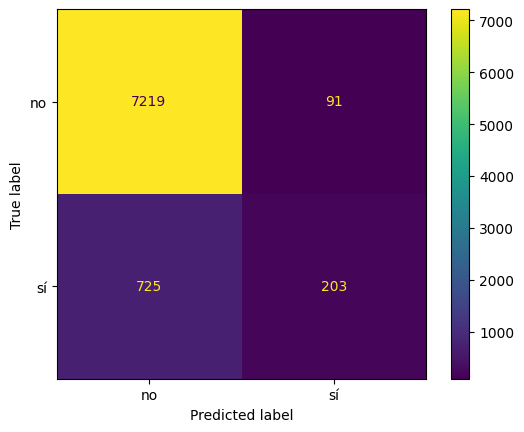

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = modelo.predict(X_test)   # usa umbral 0.5 por defecto

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

ConfusionMatrixDisplay(cm, display_labels=["no", "sí"]).plot()

Una vez entrenado el modelo, generamos las predicciones sobre el conjunto de prueba usando el umbral de 0.5, es decir, el modelo responde "sí" cuando la probabilidad de que el cliente acepte es de al menos 50%.

Con estas predicciones construimos la matriz de confusión, que nos permite ver en dónde acierta y en dónde se equivoca el modelo. Para el banco esto se traduce en ventas logradas, llamadas desperdiciadas, ventas perdidas y llamadas que se evitaron.

| Valor | Nombre | Realidad | Predicción | Significado para el banco |
|---|---|---|---|---|
| 7219 | Verdaderos negativos (TN) | No aceptó | No | Llamadas que se evitaron correctamente |
| 91 | Falsos positivos (FP) | No aceptó | Sí | Llamadas desperdiciadas |
| 725 | Falsos negativos (FN) | Sí aceptó | No | Ventas perdidas |
| 203 | Verdaderos positivos (TP) | Sí aceptó | Sí | Ventas logradas |

In [6]:
exactitud      = (tp + tn) / (tp + tn + fp + fn)
precision      = tp / (tp + fp)
sensibilidad   = tp / (tp + fn)
especificidad  = tn / (tn + fp)
f1             = 2 * precision * sensibilidad / (precision + sensibilidad)

pd.Series({"Exactitud": exactitud, "Precisión": precision,
           "Sensibilidad": sensibilidad, "Especificidad": especificidad,
           "F1": f1}).round(3)

,0
Exactitud,0.901
Precisión,0.690
Sensibilidad,0.219
Especificidad,0.988
F1,0.332


Calculamos las métricas directamente a partir de los cuatro valores de la matriz de confusión.

|  | Predijo "no" | Predijo "sí" |
|---|---|---|
| **Realmente "no"** | TN (verdadero negativo) | FP (falso positivo) |
| **Realmente "sí"** | FN (falso negativo) | TP (verdadero positivo) |

 Cada métrica responde una pregunta distinta, por ejemplo, la precisión nos dice qué tan bien se aprovechan las llamadas y la sensibilidad nos dice cuántos de los clientes interesados logramos detectar. Entonces, revisarlas juntas nos da una idea más completa del desempeño del modelo que la exactitud por sí sola.

 La métrica que más le importa al banco es la sensibilidad, ya que cada cliente que habría aceptado y no se llamó representa una venta perdida, mientras que una llamada a alguien que no acepta solo cuesta el precio de la llamada. Entonces, para el banco es más grave dejar pasar a un cliente interesado que hacer algunas llamadas de más. Con el umbral de 0.5 el modelo detecta pocos de los clientes que sí aceptan, lo cual indica que este umbral no es el más adecuado para el problema.

### Grafica la curva ROC y la curva de precisión contra sensibilidad, con su AUC y su precisión promedio. En scikit-learn, RocCurveDisplay y PrecisionRecallDisplay. ¿Qué muestra la segunda que la primera esconde cuando los positivos son pocos?



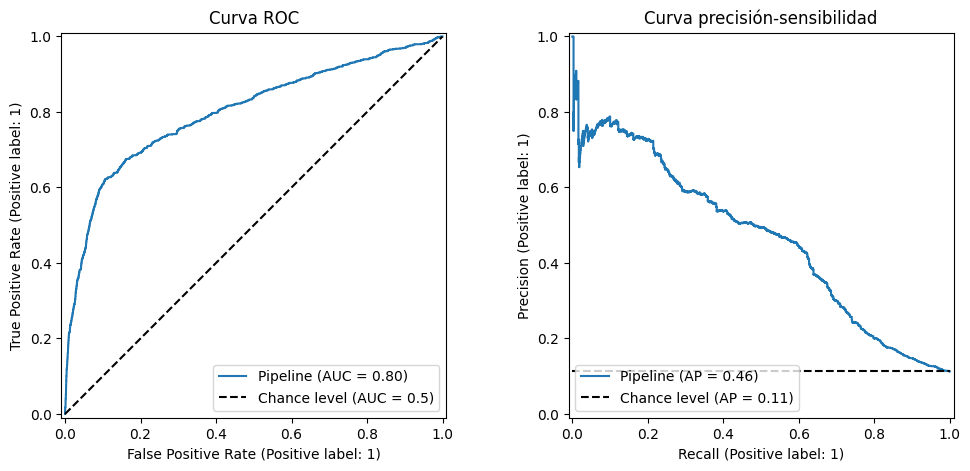

In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(modelo, X_test, y_test, ax=axes[0], plot_chance_level=True)
PrecisionRecallDisplay.from_estimator(modelo, X_test, y_test, ax=axes[1], plot_chance_level=True)
axes[0].set_title("Curva ROC")
axes[1].set_title("Curva precisión-sensibilidad")
plt.show()

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score
# Devuelve dos columnas: la probabilidad de “no” y la de “sí”
proba = modelo.predict_proba(X_test)[:, 1]
print("AUC:", roc_auc_score(y_test, proba))
print("AP: ", average_precision_score(y_test, proba))

AUC: 0.800785340700033
AP:  0.46481973058365406


La curva ROC obtiene un AUC de 0.8007, lo que parece un buen desempeño, mientras que la curva de precisión contra sensibilidad tiene una precisión promedio de 0.4648, un valor bastante más bajo. La curva de precisión contra sensibilidad, en cambio compara esos errores directamente con los clientes que sí aceptaron, y de esta forma muestra lo difícil que es encontrar a los pocos positivos sin desperdiciar llamadas.

### Cada llamada cuesta 5, acepte o no el cliente, y cada cliente que acepta deja un ingreso de 50. ¿A partir de qué probabilidad conviene llamar? Compara en prueba la ganancia total con el umbral de 0.5 y con el tuyo.

In [9]:
import numpy as np

proba = modelo.predict_proba(X_test)[:, 1]

def ganancia(y_real, proba, umbral, costo=5, ingreso=50):
    llamar = proba >= umbral
    aceptan = (llamar & (y_real == 1)).sum()
    return ingreso * aceptan - costo * llamar.sum(), llamar.sum(), aceptan

for u in [0.5, 0.1]:
    g, llamadas, ventas = ganancia(y_test.values, proba, u)
    print(f"Umbral {u}: ganancia = {g}, llamadas = {llamadas}, ventas = {ventas}")

Umbral 0.5: ganancia = 8680, llamadas = 294, ventas = 203
Umbral 0.1: ganancia = 22100, llamadas = 1900, ventas = 632


- **`proba`** obtiene la probabilidad de "sí" para cada cliente de prueba.
- **La función `ganancia`** recibe un umbral y:
  - marca como `llamar` a los clientes cuya probabilidad lo supera;
  - cuenta cuántos de esos llamados realmente aceptaron (`aceptan`);
  - calcula la ganancia como 50 por cada venta menos 5 por cada llamada.
- **El ciclo `for`** la evalúa con ambos umbrales e imprime ganancia, llamadas y ventas, para que veas de dónde sale la diferencia.
- **`.values`** convierte `y_test` en un arreglo de numpy, para que la comparación con `llamar` se haga posición por posición sin problemas de índices.

Conviene llamar a un cliente cuando la ganancia esperada de la llamada es positiva, es decir, cuando 50·p − 5 > 0, lo que da un umbral de p = 0.1. Con el umbral de 0.5 el banco obtiene una ganancia de 8,680 en prueba, mientras que con el umbral de 0.1 obtiene 632, ya que aunque hace más llamadas que no se concretan, logra detectar a muchos más clientes que sí aceptan. Entonces, el umbral de 0.5 resulta demasiado conservador para este problema, porque descarta clientes con probabilidades bajas que aun así dejan ganancia.

### La variable que quitaste. Repite el punto 3 incluyéndola. ¿Qué les pasa a las métricas? ¿Le servirían al banco?

In [10]:
# Incluimos duration
X_dur = df.drop(columns="y")
y_dur = df["y"]

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_dur, y_dur, test_size=0.2, stratify=y_dur, random_state=42
)

num_d = Xd_train.select_dtypes(include="number").columns
cat_d = Xd_train.select_dtypes(exclude="number").columns

modelo_dur = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), num_d),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_d),
    ])),
    ("logreg", LogisticRegression(max_iter=1000)),
])
modelo_dur.fit(Xd_train, yd_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object'))])),
                ('logreg', LogisticRegression(max_iter=1000))])

Ahora la matriz de confusión y comparación de métricas.

,Sin duration,Con duration
Exactitud,0.901,0.917
Precisión,0.690,0.712
Sensibilidad,0.219,0.436
Especificidad,0.988,0.978
F1,0.332,0.541


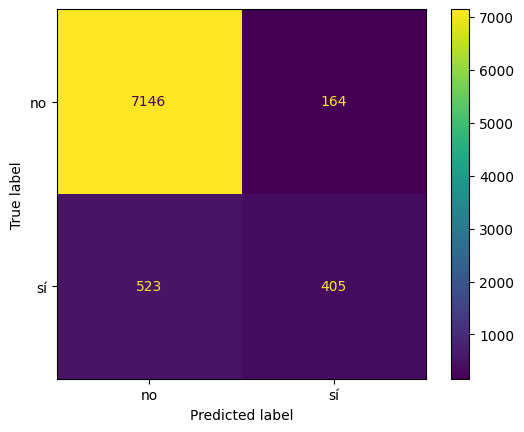

In [11]:
def metricas(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    p, s = tp / (tp + fp), tp / (tp + fn)
    return {"Exactitud": (tp + tn) / (tp + tn + fp + fn), "Precisión": p,
            "Sensibilidad": s, "Especificidad": tn / (tn + fp),
            "F1": 2 * p * s / (p + s)}

yd_pred = modelo_dur.predict(Xd_test)
ConfusionMatrixDisplay(confusion_matrix(yd_test, yd_pred), display_labels=["no", "sí"]).plot()

pd.DataFrame({"Sin duration": metricas(y_test, y_pred),
              "Con duration": metricas(yd_test, yd_pred)}).round(3)

Al incluir duration, las métricas mejoran de forma notable, en especial la sensibilidad, que pasa de 0.219 a 0.436, lo cual indica que el modelo detecta muchos más clientes que sí aceptan. Sin embargo, esta mejora no le serviría al banco, ya que la duración de la llamada solo se conoce después de haber llamado, y para ese momento la decisión de a quién llamar ya se tomó. Entonces, el modelo con duration no está prediciendo quién va a aceptar, sino reconociendo llamadas que ya resultaron exitosas, y por eso solo vale la pena usarlo como referencia, tal como recomiendan los autores.

## Declaración de uso de inteligencia artificial
Se utilizó un modelo de inteligencia artificial (Anthropic, Claude Opus 5.5) como asistente para repasar los conceptos de regresión y clasificación, organizar la estructura del notebook con base en el notebook de clase, proponer y depurar el código, proponer borradores de las lecturas de resultados y de la conclusión, y revisar la ortografía y el formato Markdown. Los borradores fueron revisados y reescritos por mi.

Todas las celdas fueron ejecutadas y sus resultados verificados por mi, quien se hace responsable del contenido final.